# Wireless Networking and Mobile Computing

### Prerequisites

This Jupyter Notebook has been tested with Visual Studio Code, running in a local Python environment (Python 3.8 or newer). The models are in the `Cellular` folder next to this notebook; keep the folder there.

**Installs**

In [3]:
# --- Installs: ensure required packages are available ---
%pip install numpy matplotlib ipympl --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


**Imports**

In [4]:
# --- Imports: libraries and functions used in this notebook ---
import numpy as np
import matplotlib.pyplot as plt

from Cellular.cellular_tools import (seed_from, link_budget, print_link_budget, pl_uma_db, pl_free_space_db,
                                     coverage_radius_free_space_m, o2i_loss_db, nisv_erp_cap_w, draw_zurich_grid,
                                     plot_sinr_vs_spacing, compare_reuse, plot_knee, path_loss_from_rsrp, uma_distance_m)
from Cellular.district import (make_district, density_summary, clickable_plots, planning_board, evaluate_plan, show_plan,
                               auto_plan, plot_designs)

### 1. Introduction

A cellular network divides an area into cells, each served by an antenna site. Planning such a network means answering two questions at once. Can a phone reach a site (coverage)? And can the site serve everyone it reaches (capacity)? Both depend on the frequency band, the distance between the sites, and how many people use the network.

We use Zurich as an example. The city covers about 88 km² and has about 450,000 residents and roughly as many jobs. An operator with a market share of 25 % therefore has about 1,300 subscribers per km² on average, and many more in the centre on a weekday. In the busiest hour of the day, a subscriber uses about 0.2 Mb/s on average: most of the time a phone is idle, and short bursts of downloads average out.

The notebook starts with a single cell: how far it reaches (section 2) and how many users it serves (section 3). It then looks at many cells that share the same frequencies (sections 4 and 5), at when a network is limited by coverage or by capacity (section 6), and at planning a network for a real Swiss district (section 7). Section 8 compares your plan with the real network. The measurements with your own phone are explained in `Network_Cellular_Measuring.ipynb`.

All models are simplified. Every number is a stated assumption, typical for a Swiss network, so you can follow and change each step.

**Declarations**

Your district and your distance to the nearest flat depend on your matriculation number.

In [5]:
# --- Declarations: editable variables for students ---
MATRICULATION = "21-715-917"     # <-- Change this. Your matriculation number

SEED = seed_from(MATRICULATION)

### 2. Coverage: How Far a Cell Reaches

#### 2.1 Link Budget

A link works if the received signal is strong enough compared with the noise. The link budget adds up all gains and losses between the transmitter and the receiver. The largest path loss a link can afford is the maximum allowed path loss (MAPL):

$$
\text{MAPL} = \text{EIRP} + G_{\text{RX}} - N - \text{SNR}_{\min}, \qquad N = -174\,\text{dBm/Hz} + 10\log_{10}(B) + NF,
$$

where
- $\text{EIRP}$: transmit power plus antenna gain minus cable loss (dBm),
- $G_{\text{RX}}$: gain of the receiving antenna (dBi),
- $N$: noise power of the receiver (dBm), with bandwidth $B$ (Hz) and noise figure $NF$ (dB),
- $\text{SNR}_{\min}$: the lowest signal-to-noise ratio at which data still gets through, about -5 dB with robust coding.

The link has to work in both directions. In the downlink, a site sends about 46 dBm (40 W) into an antenna with a gain of 17 dBi. In the uplink, a phone sends at most 23 dBm (0.2 W), and at the edge of a cell it gets only a small part of the band, about 1 MHz. The base station antenna helps in both directions, but it cannot make up for the weak phone. The direction with the smaller MAPL limits the size of the cell.

#### 2.2 Path Loss in a City

In free space, the path loss grows with $20\log_{10}(d)$. A model with free-space path loss, the phone's 23 dBm and a receiver sensitivity of -90 dBm gives a 700 MHz cell a radius of about 30 km. In a city, buildings block, reflect and diffract the signal, and such a model is far too optimistic: coverage would never limit a network, and the frequency would hardly matter.

The 3GPP urban macro model (TR 38.901) fits measurements in cities much better. Without a line of sight, its path loss in dB is

$$
L_{\text{UMa}} = 13.54 + 39.08\log_{10}(d) + 20\log_{10}(f),
$$

where
- $d$: distance between the site and the phone (m),
- $f$: carrier frequency (GHz).

The loss grows almost twice as fast with distance as in free space. Most phones are indoors, so the signal also has to pass walls and windows. This building entry loss grows with frequency: in modern buildings with coated glass and concrete, it is about 18 dB at 700 MHz and about 27 dB at 3.5 GHz.

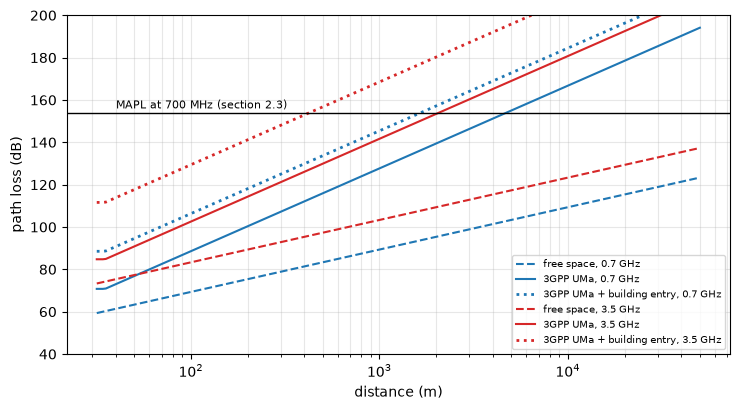

free-space model: radius 30.4 km at 700 MHz, 6.1 km at 3.5 GHz


In [6]:
d = np.logspace(1.5, 4.7, 200)          # 30 m to 50 km
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for f, col in ((0.7, "tab:blue"), (3.5, "tab:red")):
    ax.semilogx(d, pl_free_space_db(d, f), "--", color=col, label=f"free space, {f} GHz")
    ax.semilogx(d, pl_uma_db(d, f), "-", color=col, label=f"3GPP UMa, {f} GHz")
    ax.semilogx(d, pl_uma_db(d, f) + o2i_loss_db(f), ":", color=col, lw=2, label=f"3GPP UMa + building entry, {f} GHz")
lb = link_budget(700)
ax.axhline(min(lb["mapl_dl_db"], lb["mapl_ul_db"]), color="k", lw=1)
ax.text(40, min(lb["mapl_dl_db"], lb["mapl_ul_db"]) + 2, "MAPL at 700 MHz (section 2.3)", fontsize=8)
ax.set(xlabel="distance (m)", ylabel="path loss (dB)", ylim=(40, 200))
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
print(f"free-space model: radius {coverage_radius_free_space_m() / 1e3:.1f} km at 700 MHz, "
      f"{coverage_radius_free_space_m(f_ghz=3.5) / 1e3:.1f} km at 3.5 GHz")

#### 2.3 Coverage at 700 MHz and 3.5 GHz

Swiss operators use two bands for 5G that work very differently:

| | 700 MHz (band n28) | 3.5 GHz (band n78) |
|---|---|---|
| Duplex | FDD: separate channels for uplink and downlink | TDD: one channel, 75 % of the time downlink |
| Bandwidth per operator | about 10 MHz | about 100 MHz |
| Antenna | passive sector antenna | adaptive antenna with beamforming |
| Role in the network | coverage | capacity |

An adaptive antenna points a narrow beam at each user. This adds about 10 dB in the downlink and about 5 dB in the uplink. The table below gives the MAPL in both directions and the resulting cell radius outdoors and indoors.

In [7]:
print_link_budget([link_budget(700), link_budget(3500, beamforming=False), link_budget(3500)])

case                   beamforming   EIRP  NISV cut  MAPL DL  MAPL UL     limit   O2I  r outdoor  r indoor
700 MHz (n28, FDD)              no     61       0.0      163      154    uplink  17.7     4715 m    1657 m
3.5 GHz (n78, TDD)              no     61       0.0      153      148    uplink  26.8     1453 m     299 m
3.5 GHz (n78, TDD)             yes     71       0.0      163      153    uplink  26.8     1950 m     401 m
(EIRP in dBm; NISV cut: dB the downlink loses to the NISV cap; MAPL and O2I in dB)


#### 2.4 The Swiss Radiation Limit (NISV)

Switzerland limits the electric field of every antenna installation at places of sensitive use, such as flats, offices and schools. The installation limits of the ordinance on non-ionising radiation (NISV) are about ten times stricter in field strength than the ICNIRP limits used in most EU countries:

| Installation transmits | Limit |
|---|---|
| only below 1 GHz (for example 700 MHz) | 4 V/m |
| only above 1.8 GHz (for example 3.5 GHz) | 6 V/m |
| in both ranges | 5 V/m |

In the main beam, the field at a distance $d$ (m) is about $E = 7\sqrt{\text{ERP}}/d$, where ERP is the effective radiated power in watts (ERP = EIRP - 2.15 dB). The beam usually points over the nearest flat, so the antenna pattern weakens the field there by about 6 dB. Small cells up to 6 W ERP are exempt from the limit.

Adaptive antennas need a special rule, because their beam moves. Since 2021, an adaptive antenna with 64 or more sub-arrays may apply the correction factor $K_{AA} = 0.10$: its beam may be up to ten times stronger than the permitted ERP, as long as an automatic power limiter keeps the 6-minute average below it. Before, the beam was assessed as if it always pointed at the nearest flat.

Your distance to the nearest flat, `D_FLAT`, is set from your matriculation number. The column "NISV cut" shows how many dB the limit takes from the downlink.

In [8]:
D_FLAT = 10 + SEED % 31          # metres to the nearest flat, set by your matriculation number (try other values too)

print(f"Nearest flat: {D_FLAT} m. NISV cap per band (two bands on one installation): "
      f"{nisv_erp_cap_w(D_FLAT):.0f} W ERP, with K_AA up to {nisv_erp_cap_w(D_FLAT, k_aa=0.10):.0f} W in the beam\n")
print_link_budget([link_budget(700, d_flat_m=D_FLAT),
                   link_budget(3500, d_flat_m=D_FLAT, adaptive=False),
                   link_budget(3500, d_flat_m=D_FLAT, adaptive=True)],
                  labels=["700 MHz", "3.5 GHz without K_AA", "3.5 GHz with K_AA"])

Nearest flat: 23 m. NISV cap per band (two bands on one installation): 537 W ERP, with K_AA up to 5372 W in the beam

case                   beamforming   EIRP  NISV cut  MAPL DL  MAPL UL     limit   O2I  r outdoor  r indoor
700 MHz                         no     59       1.5      161      154    uplink  17.7     4715 m    1657 m
3.5 GHz without K_AA           yes     59      11.5      151      153  downlink  26.8     1780 m     366 m
3.5 GHz with K_AA              yes     69       1.5      161      153    uplink  26.8     1950 m     401 m
(EIRP in dBm; NISV cut: dB the downlink loses to the NISV cap; MAPL and O2I in dB)


### 3. Capacity: How Many Users a Cell Serves

#### 3.1 Capacity per Site

All users of a cell share its capacity. The capacity of a site with three sectors is

$$
C_{\text{site}} = 3 \cdot B \cdot \overline{\eta}, \qquad \eta = \min\left(0.75 \log_2(1 + \text{SINR}),\ 5.5\right),
$$

where
- $B$: bandwidth of each sector (Hz),
- $\eta$: spectral efficiency of a user (b/s/Hz), averaged over all users,
- $\text{SINR}$: signal to interference and noise ratio of the user (section 4).

The factor 0.75 accounts for real coding and overhead compared with Shannon's limit, and 5.5 b/s/Hz is about the most the best modulation carries.

The demand per km² is the number of subscribers per km² times their rate in the busiest hour. If the demand in a cell exceeds its capacity, the cells have to become smaller. This is called cell splitting: halving the cell radius gives four times as many cells, and so four times the capacity per km².

#### 3.2 A Regular Grid in Zurich

The grid below uses the indoor radius of section 2.3 for coverage and the capacity of one site for capacity, and takes the smaller of the two. With `gauss_strength` above 0, the users crowd into the centre while the grid stays the same; red sites cannot serve their local demand.

[note] map not loaded: [Errno 2] No such file or directory: '../../Admin/picture/zurich_map.jpg'


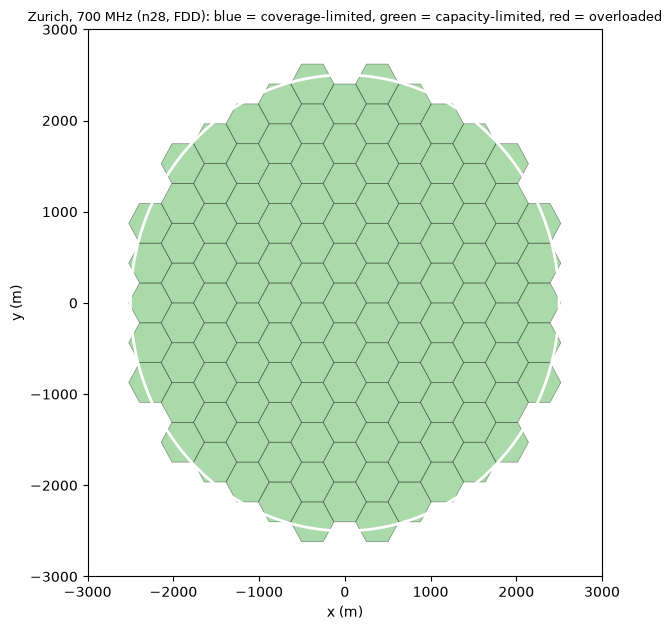

Network summary
  subscribers 115,000 on 88 km2 = 1,307 per km2, 0.20 Mb/s each
  coverage radius (indoor, uplink-limited): 1,657 m
  capacity radius (43 Mb/s per site): 252 m
  cell radius used: 252 m -> capacity-limited
  sites inside the circle: 121 (0 overloaded with gauss_strength = 0.0)


In [9]:
# --- Declarations: a regular network for central Zurich ---
subscribers        = 115_000     # <-- Change this. Subscribers of one operator in the city (25 % of 460,000)
data_rate_per_user = 0.2e6       # <-- Change this. Rate per subscriber in the busiest hour (b/s)
frequency_mhz      = 700         # <-- Change this. 700 or 3500
gauss_strength     = 0.0         # <-- Change this. 0 = uniform, 1 = strongly concentrated in the centre

draw_zurich_grid(subscribers, data_rate_per_user, frequency_mhz, gauss_strength)

### 4. Interference

All cells of a network use the same frequencies. A phone therefore hears its own site and, weaker, all the other sites. The quality of its signal is

$$
\text{SINR} = \frac{S}{I + N},
$$

where
- $S$: power received from the serving site,
- $I$: sum of the power received from all other sites,
- $N$: noise power.

When the sites are far apart, the other sites are weak and the noise dominates. Such a network is noise-limited, and more transmit power improves the SINR. When the sites are close together, the other sites dominate: the network is interference-limited. More power then raises the signal and the interference equally, and the SINR does not improve.

The model below places sites with three sectors on a hexagonal grid at 3.5 GHz, with 2,500 indoor users at random positions. It uses the path loss of section 2 and random shadowing of 7 dB. The plot shows the median SINR against the distance between the sites, at full power and at one tenth of the power.

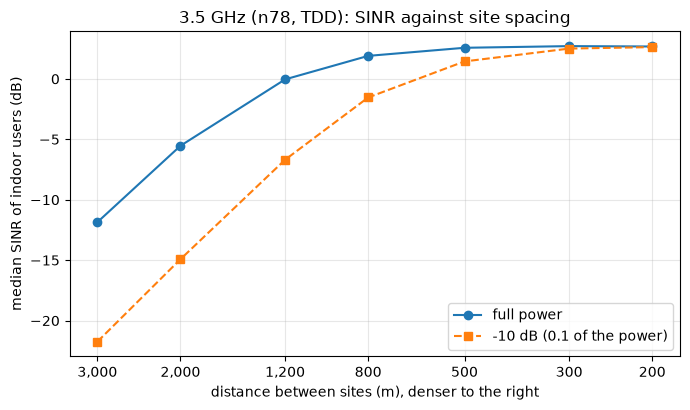

In [10]:
POWER_OFFSETS_DB = (0, -10)      # <-- Change this. 0 = full power, -10 = one tenth of the power

sweep = plot_sinr_vs_spacing(power_offsets_db=POWER_OFFSETS_DB)

### 5. Frequency Reuse

GSM networks divided their frequencies into groups and gave neighbouring cells different groups, like colouring a map so that no two neighbours share a colour. This is called reuse 3 (or 7, or 12, depending on the number of groups). Each cell then has only part of the spectrum, but little interference.

LTE and 5G use reuse 1: every cell uses the whole band. Neighbouring cells on the same frequency are told apart by their physical cell ID (PCI). LTE has 504 PCIs and 5G 1,008. The PCI sets the reference signals and the scrambling of a cell, so a phone can measure each neighbour separately, even on the same frequency. Operators plan the PCIs so that neighbours differ, and they handle the remaining interference with scheduling and power control instead of separate frequencies.

You can observe this with your phone: at two positions a few hundred metres apart, the PCI often changes while the band stays the same.

The comparison below uses the model of section 4 with sites 500 m apart.

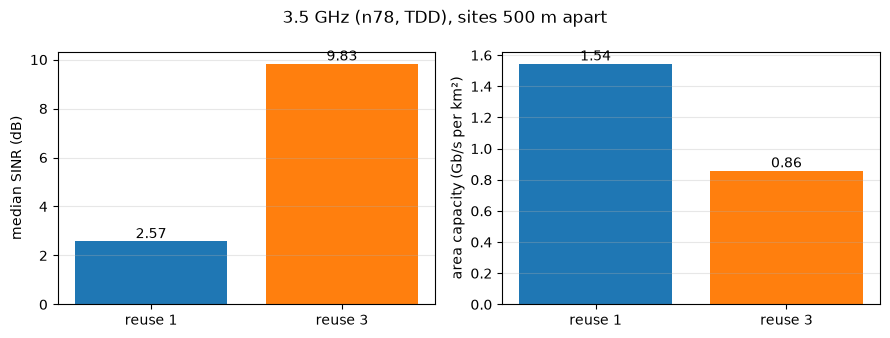

reuse 1: median SINR   2.6 dB, capacity per site   334 Mb/s, area capacity 1.54 Gb/s per km²
reuse 3: median SINR   9.8 dB, capacity per site   186 Mb/s, area capacity 0.86 Gb/s per km²


In [11]:
reuse = compare_reuse(isd_m=500)

### 6. Coverage or Capacity: The Knee

How many sites per km² does a network need? It needs enough sites to cover the area, and enough sites to carry the demand, so the larger of the two numbers counts:

$$
\text{sites per km}^2 = \max\left(\frac{1}{2.6\, r^2},\ \frac{\text{subscribers per km}^2 \cdot 0.2\ \text{Mb/s}}{C_{\text{site}}}\right),
$$

where
- $r$: indoor cell radius from section 2.3 (km); a site with three sectors covers about $2.6\, r^2$,
- $C_{\text{site}}$: capacity of one site from section 3 (Mb/s).

The plot shows this number against the density of subscribers, for each band. Where few people live, the curve is flat: the sites are needed to cover the area, and they have capacity to spare. The network is coverage-limited. Where many people live, the curve rises: each additional subscriber needs capacity, so more sites are needed. The network is capacity-limited. The point where the curve bends is called the knee.

The two bands have very different knees. 700 MHz reaches far but carries little, so it becomes capacity-limited early. 3.5 GHz carries a lot but reaches less far, so it needs many sites before capacity matters. Real networks use both on the same sites: 700 MHz for coverage, 3.5 GHz where capacity is needed.

The dashed vertical lines show the densities of your district, the same district as in section 7.

Zurich: subscribers of one operator per km2 (25% market share)
   weekday 11:00, average           3,325
   weekday 11:00, busiest 1 %      37,066
   evening 21:00, average           2,061
   evening 21:00, busiest 1 %       8,431
   real macro installations (all operators): 334, 13.4 per km2


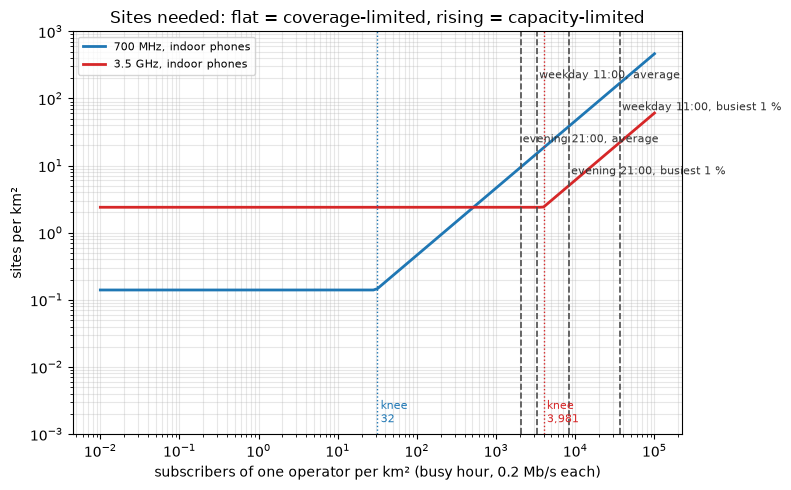

capacity per 3-sector site: 700 MHz 43 Mb/s, 3.5 GHz 330 Mb/s
knees: 700 MHz 32, 3.5 GHz 3,981 subscribers per km²


In [12]:
reg = make_district(MATRICULATION)
dens, real_sites_per_km2 = density_summary(reg)

knee = plot_knee(dens)

### 7. Planning a Network for Your District

You now plan the network of a new operator in a real Swiss city centre of 5 × 5 km, chosen by your matriculation number. The data for each hectare is real: residents, jobs and buildings from the Federal Statistical Office, and the existing antenna sites from the Federal Office of Communications (OFCOM). Your operator has 25 % of the people as customers, each using 0.2 Mb/s in the busiest hour.

You can build three kinds of sites, at illustrative costs over five years:

| Site | Cost | Properties |
|---|---|---|
| Share an existing rooftop | CHF 150k | cheap, but the operators already there use most of the NISV limit, so little power is left |
| New rooftop site | CHF 320k | the full NISV limit, depending on the distance to the nearest flat |
| Small cell | CHF 45k | 3.5 GHz only, at most 6 W ERP (exempt from the NISV limit), short range |

Each site also needs a connection to the network: fibre for CHF 40k in built-up blocks, or microwave for CHF 25k elsewhere.

The board decides for every hectare which band serves it. It uses 3.5 GHz if the SINR there is at least 0 dB, otherwise 700 MHz if the SINR is at least -6 dB, and only if the phone's uplink reaches the site. Each sector shares its capacity among the hectares it serves, and a busy sector interferes more with its neighbours. The colours show what limits each hectare:

| Colour | Meaning |
|---|---|
| green | served: the hectare gets all of its demand |
| orange | capacity-limited: covered, but its sector is overloaded |
| purple | interference-limited: a site is in reach, but the neighbours drown it |
| red | coverage-limited: no site in reach, in the downlink or the uplink |

On the right of the board, you can switch the hour and the limits. On a weekday at 11:00, the jobs are in the centre; in the evening at 21:00, people are at home. The limits are the NISV assessed without $K_{AA}$, the NISV with $K_{AA}$, or the ICNIRP limits of most EU countries. With $K_{AA}$, a 3.5 GHz sector may beam up to ten times stronger, but only while its 6-minute average stays below the permit, so a sector that is busy all the time gains little.

The cell below makes the figures in this notebook clickable (`%matplotlib widget`, from the package `ipympl`) and draws your board. Click a site to add or remove it, and click a hectare to see what limits it. The numbers update at once. To keep a design, store its plan string with the cell after it.

If clickable figures do not work on your computer, the board is drawn as a picture with every site numbered. Then give the sites as a list, for example `planning_board(reg, plan=[3, 17, 42], hour="day", limits="nisv_kaa")`, and run the cell again. The hour is `"day"` or `"evening"`, the limits `"nisv"`, `"nisv_kaa"` or `"icnirp"`. If the board does not appear at all, run `%matplotlib inline` in a cell first.

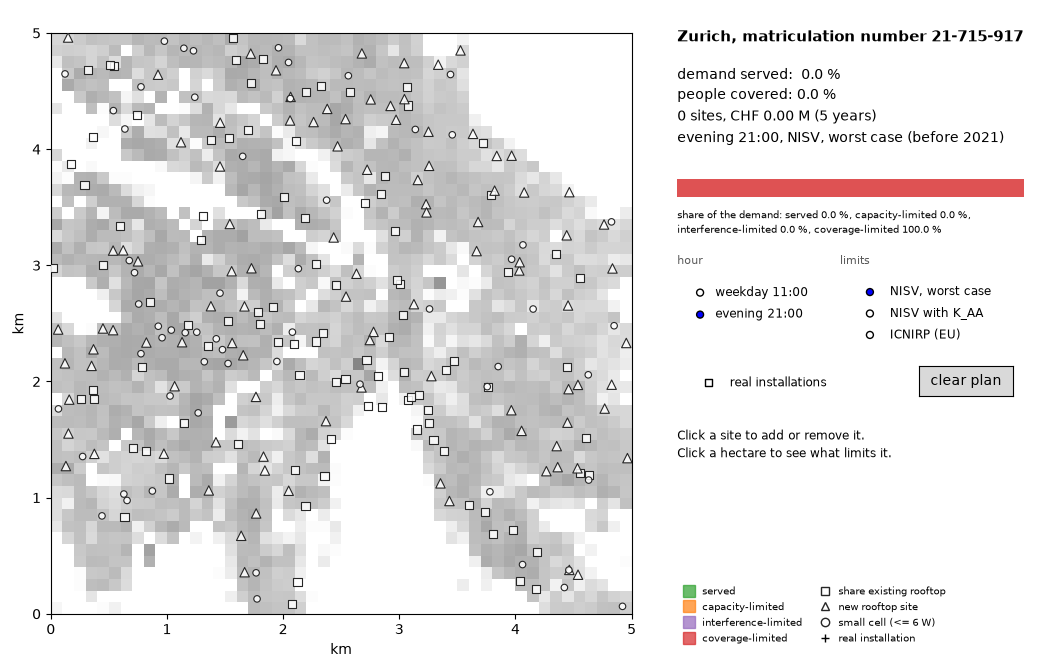

In [13]:
clickable_plots()                # figures in this notebook react to the mouse from here on
board = planning_board(reg)      # <-- Or start from a list or a plan string: planning_board(reg, plan=[3, 17, 42])

In [20]:
# --- Keep a design: after clicking, store its plan string (PLAN_B, PLAN_C, ... for the next ones) ---
PLAN_A = {"matriculation": "21-715-917", "district": "Zurich", "hour": "evening", "limits": "nisv", "plan": [6, 30, 35, 48, 56, 60, 63, 82, 96, 101, 111, 161, 166, 185, 197, 234]}
PLAN_B = board.plan_string       # <-- Change this.
print(PLAN_B)
res_b = evaluate_plan(reg, PLAN_B)

{"matriculation": "21-715-917", "district": "Zurich", "hour": "evening", "limits": "nisv", "plan": [6, 8, 15, 23, 29, 30, 33, 35, 48, 56, 60, 63, 66, 82, 96, 101, 111, 112, 117, 118, 123, 127, 161, 165, 166, 167, 175, 185, 197, 234]}
Zurich, evening 21:00, NISV, worst case (before 2021): 30 sites, CHF 7.92 M, demand served 61.9 %, people covered 99.6 %
   demand that is capacity-limited 50.6 %, interference-limited 0.4 %, coverage-limited 0.0 %


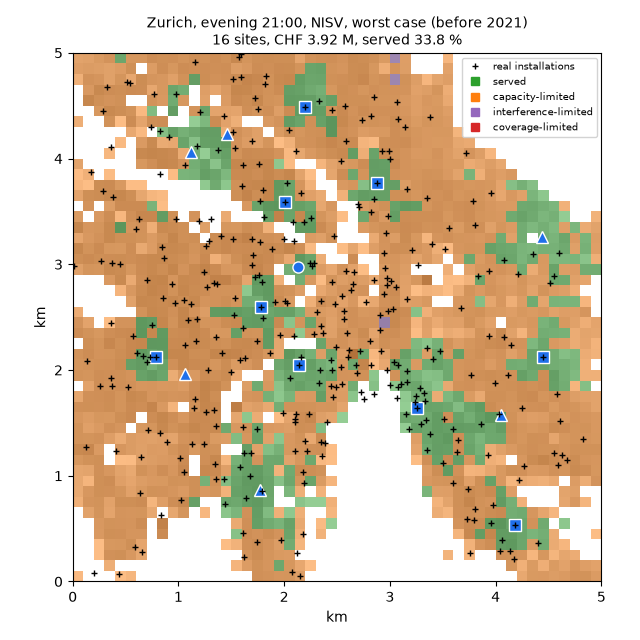

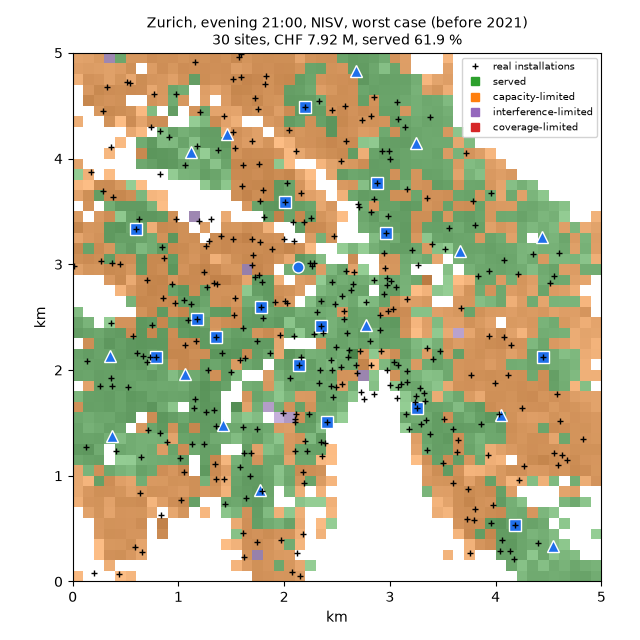

In [22]:
res_a = show_plan(reg, PLAN_A, real_sites=True)    # a picture of a design, with the real installations
res_b = show_plan(reg, PLAN_B, real_sites=True)    # a picture of a design, with the real installations

#### 7.1 Comparing Designs

`auto_plan` is a simple automatic planner. It keeps adding the site that serves the most additional demand per franc until the budget is spent. It plans for the evening under the NISV, unless you give it `hour` and `limits` like the board. Use it to compare with your own plans.

Compare all designs on one chart. A design is dominated if another design serves at least as much demand for less money. The designs that are not dominated form the Pareto front: the best trade-offs between cost and demand served.

auto_plan: 22 sites, CHF 3.99 M, served 53.3 %
auto_plan: 37 sites, CHF 7.97 M, served 81.9 %


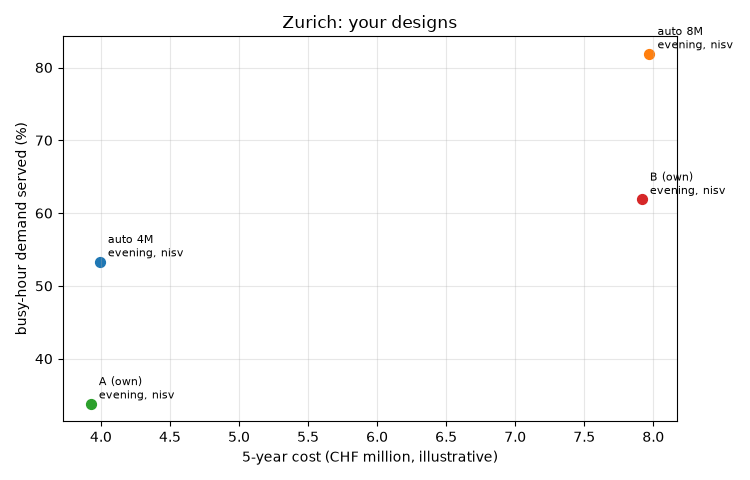

design           hour    limits  sites   CHF M   served  covered
auto 4M       evening      nisv     22    3.99    53.3%    99.9%
auto 8M       evening      nisv     37    7.97    81.9%    99.8%
A (own)       evening      nisv     16    3.92    33.8%    99.8%
B (own)       evening      nisv     30    7.92    61.9%    99.6%


In [21]:
# --- Your designs: label -> plan string (from the board or from auto_plan) ---
designs = {
    "auto 4M": auto_plan(reg, budget_chf=4e6),                     # <-- Change this.
    "auto 8M": auto_plan(reg, budget_chf=8e6),                     # <-- Change this.
    "A (own)": PLAN_A,                                           # <-- Add your own designs.
    "B (own)": PLAN_B,                                           # <-- Add your own designs.
}
rows = plot_designs(reg, designs)

### 8. The Real Network

Your plan is the network of one operator in a model. The real network has three operators, several bands on each site, sectors, small cells and systems inside buildings. The board shows the real installations of your district on its map, and the OFCOM map shows every antenna site in Switzerland: [map.geo.admin.ch, mobile antenna sites](https://map.geo.admin.ch/?layers=ch.bakom.standorte-mobilfunkanlagen).

Your outdoor RSRP from `Network_Cellular_Measuring.ipynb` gives a rough distance to your site. If the site transmits with the typical power of section 2, the RSRP gives the path loss, and the urban macro model turns it into a distance. Real sites differ, so this is only an estimate.

In [17]:
RSRP_OUTDOOR_DBM = -92           # <-- Change this. Your outdoor RSRP (dBm)
BAND_MHZ         = 1800          # <-- Change this. Frequency of your outdoor band (MHz)
CHANNEL_MHZ      = 20            # <-- Change this. Channel bandwidth if shown (LTE often 10 or 20 MHz)

pl = path_loss_from_rsrp(RSRP_OUTDOOR_DBM, bw_mhz=CHANNEL_MHZ)
print(f"outdoor path loss about {pl:.0f} dB -> about {uma_distance_m(pl, BAND_MHZ):.0f} m to the site (3GPP UMa)")
print(f"real macro installations in {reg.name}: {len(reg.real_sites)}, {real_sites_per_km2:.1f} per km2 (all operators)")

outdoor path loss about 122 dB -> about 447 m to the site (3GPP UMa)
real macro installations in Zurich: 334, 13.4 per km2 (all operators)
